[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Alokothro/movie-recommender-svd/blob/main/notebooks/03_low_rank.ipynb)

# Project 2: A Movie Recommendation System
## Milestone 3 — Low-Rank Prediction with the SVD
*MATH 344L: Applied Linear Algebra Lab*

In Milestone 2 we hid a test set and found the score to beat: **0.9545** (user + movie effects). Now we finally get to use the SVD. The idea is that people's tastes come from a few hidden patterns, so the ratings matrix should be close to a low-rank matrix, and a low-rank approximation can fill in the missing ratings.

The catch is that the SVD needs a complete matrix, and ours is about 95% empty. So each model has to make temporary guesses for the gaps first. We try three different ways of doing that and compare them with the baseline.

**Key idea:** we choose model settings (like the rank k) with a separate **validation set**, not the test set. The test set only gets used once, at the very end, so its score is still an honest check.

- **fit:** the ratings we build models from
- **validation:** the ratings we use to pick the model and the rank
- **test:** the hidden ratings from Milestone 2, scored once at the end

## Part A: Load your project functions and data

In [1]:
import os
import subprocess
import sys

USER = "Alokothro"
REPO = "movie-recommender-svd"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True)

sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

Cloning into 'movie-recommender-svd'...


This cell gets my own Milestone 2 code from GitHub so I don't have to paste those functions in again. If the repo folder is already there (like if I rerun the notebook in the same Colab session), `git pull` just updates it. Otherwise `git clone` downloads it. `check=True` makes the cell stop with an error if git fails instead of quietly moving on. Any message printed under the cell is just git saying what it did.

`sys.path.insert(0, f"{REPO}/src")` adds the repo's `src` folder to the places Python looks for code, so `from evaluate import ...` finds `src/evaluate.py` and `from models import ...` finds `src/models.py`. Now `split_ratings`, `to_matrix`, `rmse`, and `bias_baseline` work exactly like they did in Milestone 2.

In [2]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip")
    zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv(
    "ml-100k/u.data", sep="\t",
    names=["user", "item", "rating", "time"])

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit:", len(fit), "validation:", len(val), "test:", len(test))

fit: 81200 validation: 8832 test: 9968


This loads MovieLens the same way as Milestone 2: it only downloads the zip if the `ml-100k` folder isn't already there. Then it splits the ratings twice:

- `split_ratings(ratings, seed=0)` is the exact same split as Milestone 2, so the test set is the same 9,968 hidden ratings and 0.9545 is still a fair score to compare against.
- `split_ratings(train, seed=1)` splits the training ratings again, into **fit** (81,200 ratings) and **validation** (8,832 ratings).

81,200 + 8,832 = 90,032, which is the whole training set from Milestone 2. The `ml-100k` folder is only downloaded for this session, and it's not saved to GitHub.

## Part B: Set up a fair validation comparison

In [3]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

def score_at(P, rows, cols, truth):
    """RMSE for selected entries of a prediction matrix."""
    pred = np.clip(P[rows, cols], 1, 5)
    return rmse(pred, truth)

`R_fit` is the user-by-movie matrix built from the fit ratings only, with `nan` in every gap, and `known_fit` is True wherever there's a fit rating. The validation ratings never go into the matrix. They're only used as answers to check against. `val_truth` holds the real validation ratings, and `val_u` and `val_i` are their rows and columns (minus 1, since Python counts from 0).

`score_at` takes a full prediction matrix `P` and pulls out just the entries we want to check. `P[rows, cols]` pairs the two lists up, so it grabs `P[val_u[0], val_i[0]]`, then `P[val_u[1], val_i[1]]`, and so on, one prediction for each validation rating. Then it clips the predictions to 1–5 stars and returns the RMSE. It stays in the notebook instead of `src` because it depends on which set we're scoring: validation for now, and test at the very end.

## Part C: Build the baseline prediction matrix

In [4]:
def baseline_matrix(R):
    """Full matrix: overall mean plus user and movie effects."""
    mu, b_user, b_item = bias_baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE:", round(baseline_val_rmse, 4))

Baseline validation RMSE: 0.9731


`baseline_matrix` turns the Milestone 2 bias baseline into a full 943 × 1682 matrix of predictions. `b_user[:, None]` makes the user effects into a column (943 × 1) and `b_item[None, :]` makes the movie effects into a row (1 × 1682). When you add a column and a row, NumPy *broadcasts* them: it stretches both into a full grid, so entry (u, i) becomes μ + b_user[u] + b_item[i]. That's a prediction for every user and every movie at once.

On validation, the baseline gets **0.9731**. That's worse than the 0.9545 from Milestone 2, but that's expected: it's built from fewer ratings (fit instead of all of train) and scored on different hidden ratings. All the models below are also built from fit and scored on validation, so **0.9731 is the number to beat on validation**.

## Part D: Create a rank-k helper

In [5]:
def rank_k(U, s, Vt, k):
    """Build a rank-k matrix from an already computed SVD."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

`rank_k` rebuilds a matrix from its SVD using only the first k pieces: the first k columns of U, the k biggest singular values, and the first k rows of Vᵀ.

$$A_k = U_k \, \Sigma_k \, V_k^T$$

The singular values come sorted from biggest to smallest, so the first k pieces are the k strongest patterns in the matrix. `np.diag(s[:k])` turns the list of singular values into the diagonal matrix Σ. Computing the SVD is the slow part, so we do it once per model and then call `rank_k` with lots of different k values, which is just matrix multiplication.

## Part E: Model 1 — fill gaps with movie averages

In [6]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
    np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

The SVD can't handle `nan`, so Model 1 fills every gap with that movie's average fit rating. `item_mean` starts out as the overall average `mu_fit` for every movie (a backup in case a movie has no fit ratings), and then every movie that has ratings gets its real average. `np.where(known_fit, R_fit, item_mean[None, :])` goes entry by entry: if there's a real rating, keep it, and if not, use that movie's average. `item_mean[None, :]` is a row, so it gets broadcast down all 943 rows.

Now `F` has no gaps, so `np.linalg.svd` can factor it. `full_matrices=False` gives the smaller version of the SVD (Vᵀ is 943 × 1682 instead of 1682 × 1682), which is faster and still has everything we need. One thing to keep in mind: about 95% of `F` is filled-in averages, not real ratings.

## Part F: Model 2 — let SVD explain what the baseline misses

In [7]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

Model 2 is smarter about what it asks the SVD to do. The baseline already handles the overall average, generous users, and popular movies, so we subtract it first. At every known entry, `R_fit - B_fit` is how much higher or lower the real rating was than the baseline guessed. That's the *deviation*. At every gap we put 0, which means "no evidence this user and movie are any different from the baseline." Then we take the SVD of that deviation matrix `X_fit`.

To predict ratings, we add the low-rank deviations back on top of the baseline:

$$\text{prediction} = B + (\text{rank-}k \text{ version of } X)$$

So the baseline does the easy part, and the SVD only has to find the leftover taste patterns, like a user who likes sci-fi more than their average would suggest.

## Part G: Choose rank using validation RMSE

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []

for k in ks:
    P1 = rank_k(U1, s1, Vt1, k)
    P2 = rank_k(U2, s2, Vt2, k) + B_fit
    val_err1.append(score_at(P1, val_u, val_i, val_truth))
    val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print("Best Model 1 k:", best_k1, "validation RMSE:", min(val_err1))
print("Best Model 2 k:", best_k2, "validation RMSE:", min(val_err2))

Best Model 1 k: 15 validation RMSE: 0.9934477108911387
Best Model 2 k: 15 validation RMSE: 0.9492241710885614


This tries 10 ranks for both models and scores each one on validation. Model 1's rank-k matrix is already in stars. Model 2's is only deviations, so we add `B_fit` back first. `np.argmin` gives the *position* of the smallest error, and `ks[...]` turns that position into the actual rank.

Both models do best at **k = 15**:
- Model 1 (fill with movie averages): 0.9934
- Model 2 (SVD of baseline deviations): 0.9492

Model 2 beats the 0.9731 baseline. Model 1's best is still worse than the baseline.

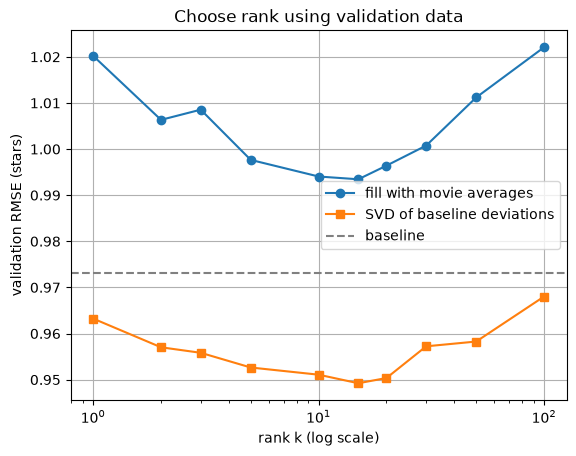

In [9]:
plt.semilogx(ks, val_err1, "o-", label="fill with movie averages")
plt.semilogx(ks, val_err2, "s-", label="SVD of baseline deviations")
plt.axhline(baseline_val_rmse, color="gray", linestyle="--",
            label="baseline")
plt.xlabel("rank k (log scale)")
plt.ylabel("validation RMSE (stars)")
plt.title("Choose rank using validation data")
plt.grid()
plt.legend()
plt.savefig("validation_rmse_vs_k.png", dpi=150)
plt.show()

This plots the same validation errors. The x-axis uses a log scale (`semilogx`) because the ranks go all the way from 1 to 100, and the gray dashed line is the baseline. Lower is better.

- **Model 1 stays above the baseline at every rank.** Most of what its SVD sees is filled-in movie averages, and those fills don't know anything about the user, so a harsh rater's gaps get the same numbers as a generous rater's.
- **Model 2 is below the baseline at every rank.** It bottoms out at k = 15 and then gets worse again at higher ranks. Past that point, the extra patterns are mostly fitting noise in the fit ratings (Exercise 4 looks at this).

The chart is saved as `validation_rmse_vs_k.png` (there's a copy in `figures/`). k = 15 is only the setting we picked. We still haven't touched the test set.

## Part H: Model 3 — iteratively improve the missing-value guesses

In [10]:
def iterative_svd_predict(R, k, n_iter=10):
    """Predict ratings by repeatedly imputing missing deviations."""
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)

    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)

    return L + B

Model 2 put a deviation of 0 in every gap and did one SVD. Model 3 keeps going: it uses the SVD's own guesses to fill the gaps, does another SVD, and repeats.

1. Start like Model 2, with real deviations at the known entries and 0s in the gaps.
2. Take the SVD and build the rank-k matrix `L`.
3. `np.where(known, R - B, L)` puts the real deviations back at the known entries (so the real data never changes) and keeps the new guesses from `L` only in the gaps.
4. Repeat `n_iter` times, then add the baseline back with `L + B`.

Each round, the gaps start from better guesses than 0, so the next SVD sees a more realistic matrix. The downside is that every round needs a brand-new SVD, so 10 rounds take about 10 times as long as Model 2.

In [11]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
    P3 = iterative_svd_predict(R_fit, k, n_iter=10)
    val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Best iterative rank: 2
Best validation RMSE: 0.9431464026691649


This tries Model 3 at ranks 2, 5, 10, and 20, with 10 rounds each. The best is **rank 2, with a validation RMSE of 0.9431**. The next cell puts it next to the other models.

In [12]:
print("Model 3 validation RMSE by rank:")
print(pd.Series(val_err3, index=ks_iter).rename_axis("rank").round(4).to_string())

comparison = pd.DataFrame({
    "best rank": ["none", best_k1, best_k2, best_k3],
    "validation RMSE": [baseline_val_rmse, min(val_err1),
                        min(val_err2), min(val_err3)],
}, index=["baseline", "Model 1: fill with movie averages",
          "Model 2: SVD of baseline deviations", "Model 3: iterative SVD"])
comparison.round(4)

Model 3 validation RMSE by rank:
rank
2     0.9431
5     0.9433
10    0.9588
20    0.9769


,best rank,validation RMSE
baseline,none,0.9731
Model 1: fill with movie averages,15,0.9934
Model 2: SVD of baseline deviations,15,0.9492
Model 3: iterative SVD,2,0.9431


With all four side by side, Model 3 has the lowest validation error, so it's the model we take to the test set, at rank 2. Rank 5 was right behind it (0.9433 vs 0.9431), so honestly 2 and 5 are basically tied.

It's interesting that iterating lets a much lower rank work: Model 2 needed 15 patterns, and Model 3 does better with just 2. Higher ranks also overfit faster when you iterate. Rank 20 gets 0.9769, which is actually worse than the baseline.

## Part I: Refit and evaluate on the test set once

In [13]:
R_train = to_matrix(train)
test_truth = test["rating"].to_numpy()
test_u = test["user"].to_numpy() - 1
test_i = test["item"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
    test_prediction = iterative_svd_predict(
        R_train, best_k3, n_iter=10)
    chosen_model = "iterative SVD"
elif min(val_err2) < min(val_err1):
    known_train = ~np.isnan(R_train)
    X_train = np.where(known_train, R_train - B_train, 0.0)
    U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k2) + B_train
    chosen_model = "baseline plus low-rank deviations"
else:
    known_train = ~np.isnan(R_train)
    mu_train = np.nanmean(R_train)
    n_item_train = known_train.sum(axis=0)
    means_train = np.full(R_train.shape[1], mu_train)
    has_train = n_item_train > 0
    means_train[has_train] = (
        np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
    F_train = np.where(known_train, R_train, means_train[None, :])
    U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k1)
    chosen_model = "SVD of movie-average-filled matrix"

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


Now that the model and rank are locked in (iterative SVD at rank 2), we rebuild it from **all** of train, fit and validation together (90,032 ratings), since more data should give a better model. The `if/elif/else` just picks whichever model had the lowest validation error and refits that one, so nothing here depends on the test set. Then we score it on the hidden test ratings, one time:

- Baseline test RMSE: **0.9545**, the same as Milestone 2 (same split, same model)
- Iterative SVD (rank 2) test RMSE: **0.9286**

So the SVD model beats the score to beat by about 0.026 stars on ratings it has never seen. It's not a huge jump, but it's real, and it's the first model to get below 0.95. We can't go back and change the rank because of this number, or the test set would just turn into another validation set.

## Part J: Make a few recommendations

In [14]:
item_info = pd.read_csv(
    "ml-100k/u.item", sep="|", header=None, usecols=[0, 1],
    encoding="latin-1")
item_info.columns = ["item", "title"]

user_id = 1
user_row = user_id - 1
unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(title, "predicted rating:", round(predicted_scores[col], 2))

Great Day in Harlem, A (1994) predicted rating: 5.0
Saint of Fort Washington, The (1993) predicted rating: 5.0
Pulp Fiction (1994) predicted rating: 5.0
Aiqing wansui (1994) predicted rating: 5.0
Santa with Muscles (1996) predicted rating: 5.0


This turns the prediction matrix into actual recommendations for user 1. `np.isnan(R_train[user_row])` finds the movies user 1 hasn't rated in training, and `np.where(...)[0]` turns that into a list of column numbers. `np.argsort` sorts those movies by predicted score from lowest to highest, `[-5:]` takes the last five (the highest), and `[::-1]` flips them so the best is first. Columns start at 0 but MovieLens IDs start at 1, so we look up `col + 1` in `u.item` to get each title.

All five come out at exactly 5.0 because their raw predictions were over 5 and got clipped. That means they're tied, so the order they print in doesn't really mean anything. The list is *Pulp Fiction*, a big popular movie, plus four obscure ones: *A Great Day in Harlem*, *Aiqing wansui*, *Santa with Muscles*, and *The Saint of Fort Washington*. Exercise 6 looks at why those show up.

A high predicted rating isn't proof user 1 would like the movie. RMSE tells us how accurate the model is on average over thousands of hidden ratings, not whether these five are good picks.

# Practice Exercises

### Exercise 1 — Does filling matter?

In [15]:
fills = {
    "movie average": item_mean[None, :],
    "overall average": mu_fit,
    "3 stars": 3.0,
    "0 stars": 0.0,
}
check_ks = [2, 5, 10, 20, 50]

fill_err = {}
for name, fill in fills.items():
    F_try = np.where(known_fit, R_fit, fill)
    Uf, sf, Vtf = np.linalg.svd(F_try, full_matrices=False)
    fill_err[name] = [score_at(rank_k(Uf, sf, Vtf, k), val_u, val_i, val_truth)
                      for k in check_ks]

pd.DataFrame(fill_err, index=pd.Index(check_ks, name="rank k")).round(4)

,movie average,overall average,3 stars,0 stars
rank k,,,,
2,1.0063,1.0728,1.1192,2.4912
5,0.9976,1.0568,1.0856,2.4036
10,0.9940,1.0511,1.0749,2.3434
20,0.9964,1.0545,1.0788,2.3508
50,1.0112,1.0716,1.1210,2.4913


I filled the gaps four different ways, took an SVD of each, and scored a few ranks on validation. I added 0 stars too, to see what happens.

**Movie average works best at every rank** (best: 0.9940 at k = 10), then the overall average (about 1.05 to 1.07), then 3 stars (about 1.07 to 1.12). That order makes sense. The closer the fill is to what people would really rate, the less fake stuff the SVD has to work around, and a movie's own average is a better guess than one number for every movie. 3 stars is also below the overall average of about 3.5, so it drags the predictions down. Even so, none of the fills beat the 0.9731 baseline, which is why Models 2 and 3 work with deviations instead.

**0 stars is awful** (about 2.3 to 2.5 stars of error). 0 isn't even a real rating, since the scale is 1 to 5. A gap means "unknown," but the SVD can't tell the difference and treats the 0s as if people really hated those movies. About 95% of the matrix is gaps, so it mostly learns "almost everything is 0," and the predictions come out way too low (lots of them below 1 star, which then get clipped up to 1). Basically, it ends up learning *which* movies people rated instead of *how much* they liked them.

### Exercise 2 — Understand the full-rank check

In [16]:
full_k = len(s2)
X_full = rank_k(U2, s2, Vt2, full_k)
print("Full rank k:", full_k)
print("Rebuilds X_fit exactly:", np.allclose(X_full, X_fit))
print("Biggest difference:", np.abs(X_full - X_fit).max())

fit_u = fit["user"].to_numpy() - 1
fit_i = fit["item"].to_numpy() - 1
fit_truth = fit["rating"].to_numpy()
P_full = X_full + B_fit
print("\nFull rank, RMSE on fit ratings:", round(score_at(P_full, fit_u, fit_i, fit_truth), 4))
print("Full rank, RMSE on validation: ", round(score_at(P_full, val_u, val_i, val_truth), 4))
print("Baseline,  RMSE on validation: ", round(baseline_val_rmse, 4))

Full rank k: 943
Rebuilds X_fit exactly: True
Biggest difference: 1.9095836023552692e-14

Full rank, RMSE on fit ratings: 0.0
Full rank, RMSE on validation:  0.9731
Baseline,  RMSE on validation:  0.9731


Full rank here means k = 943, which is every singular value there is (the matrix only has 943 rows, so it can't have more). Keeping all of them means nothing gets thrown away, so U Σ Vᵀ rebuilds `X_fit` exactly. The biggest difference is basically zero, just computer rounding error.

That's the whole problem. `X_fit` has a 0 in every gap, so the full-rank version also has a 0 in every gap, and adding the baseline back just gives the baseline. That's why the full-rank validation score is exactly the baseline's score, 0.9731.

It also gets 0 error on the fit ratings, because it's just copying them back. So it looks perfect on ratings it has already seen and is no better than the baseline on anything new. It didn't learn any preferences. It memorized the matrix, made-up 0s included. The SVD only helps when k is small, because then it has to describe all 943 users with a few shared patterns, and those shared patterns are what let it make real guesses for the gaps.

### Exercise 3 — Study iteration

In [17]:
rounds = [1, 2, 5, 10]
iter_err = []
for n in rounds:
    P = iterative_svd_predict(R_fit, 5, n_iter=n)
    iter_err.append(score_at(P, val_u, val_i, val_truth))

print("Model 2 at rank 5:", round(val_err2[ks.index(5)], 4))
pd.DataFrame({"validation RMSE (rank 5)": iter_err},
             index=pd.Index(rounds, name="rounds")).round(4)

Model 2 at rank 5: 0.9526


,validation RMSE (rank 5)
rounds,
1,0.9526
2,0.9456
5,0.9411
10,0.9433


**No, more iteration doesn't always help.** The error drops a lot at first (0.9526 → 0.9456 → 0.9411), but going from 5 rounds to 10 it goes back *up* a little, to 0.9433.

One round gives exactly the same score as Model 2 at rank 5 (0.9526). That makes sense, because the first round starts with 0s in the gaps just like Model 2 does. After that, each round fills the gaps with better guesses than 0, which helps. But those 0s were also pulling the predictions toward the baseline, which kept the model from going too far. With every round that pull gets weaker, and eventually the rank-5 patterns are only being fit to the known ratings, noise included, so the model starts to overfit. That means the number of rounds is another setting we should pick with validation, just like the rank.

### Exercise 4 — Check for overfitting

In [18]:
fit_err2 = []
for k in ks:
    P2 = rank_k(U2, s2, Vt2, k) + B_fit
    fit_err2.append(score_at(P2, fit_u, fit_i, fit_truth))

print("Chosen model test RMSE:", round(test_rmse, 4))
pd.DataFrame({"fit RMSE": fit_err2, "validation RMSE": val_err2},
             index=pd.Index(ks, name="rank k (Model 2)")).round(4)

Chosen model test RMSE: 0.9286


,fit RMSE,validation RMSE
rank k (Model 2),,
1,0.9099,0.9632
2,0.8978,0.9570
3,0.8893,0.9558
5,0.8734,0.9526
10,0.8428,0.9511
15,0.8163,0.9492
20,0.7916,0.9504
30,0.7473,0.9572
50,0.6712,0.9583


The fit column is the error on the ratings Model 2 was built from, and the validation column is the error on ratings it never saw. As k goes up, the fit error keeps dropping, from 0.9099 at k = 1 all the way to 0.5250 at k = 100, because more patterns let it match the fit ratings more and more closely. The validation error only drops until k = 15 (0.9492) and then climbs back up to 0.9680. That growing gap is overfitting: after about 15 patterns, the extra ones are memorizing noise in the fit ratings, and that noise doesn't carry over to new ratings. Model 3 does the same thing, even faster (rank 20 was worse than the baseline).

The single final test RMSE (0.9286) is actually a bit lower than the best validation score (0.9431). That's mostly because the final model was refit on all of train, 90,032 ratings instead of 81,200, and because the test set is a different random set of ratings. It's in the same range, so the validation scores gave us a fair idea of how the model would do.

**Why pick the rank before looking at test?** If we tried every rank on the test set and kept the best one, we'd be picking the rank that happens to match those specific 9,968 ratings best. Part of that would just be luck (like the seed changes in Milestone 2), so the test score would look better than the model really is, and we'd have no honest score left. Choosing with validation keeps the test set as a true "never seen it" check.

### Exercise 5 — Cold-start limitation

In [19]:
mu_train, b_user_train, b_item_train = bias_baseline(R_train)
n_ratings = (~np.isnan(R_train)).sum(axis=0)

# u.item lists the movies in ID order, so row j matches column j
new_user = pd.DataFrame({
    "title": item_info["title"].to_numpy(),
    "score": mu_train + b_item_train,
    "training ratings": n_ratings,
})

print("Top 5 for a brand-new user (mu + b_item):")
print(new_user.nlargest(5, "score").round(2).to_string(index=False))
print("\nSame thing, only movies with at least 50 ratings:")
print(new_user[new_user["training ratings"] >= 50]
      .nlargest(5, "score").round(2).to_string(index=False))

Top 5 for a brand-new user (mu + b_item):
                               title  score  training ratings
       Great Day in Harlem, A (1994)   5.43                 1
                Aiqing wansui (1994)   5.27                 1
           Santa with Muscles (1996)   5.02                 2
Saint of Fort Washington, The (1993)   4.99                 2
       Someone Else's America (1995)   4.90                 1

Same thing, only movies with at least 50 ratings:
                                                 title  score  training ratings
                                 Close Shave, A (1995)   4.44               102
                               Schindler's List (1993)   4.36               270
                            Wrong Trousers, The (1993)   4.35               107
Wallace & Gromit: The Best of Aardman Animation (1996)   4.34                59
                      Shawshank Redemption, The (1994)   4.34               251


For a brand-new user the model has nothing to go on. Their row in the matrix is all `nan`, so their `b_user` would be an average of nothing, and their row of deviations is all 0s, so the SVD part adds nothing either. The best it can do is treat them like an average user, set b_user = 0, and predict μ + b_item. That means **every new user gets the exact same list**, basically "the most liked movies."

And that list isn't even good. The top five are all obscure movies with only 1 or 2 ratings, because one person giving a movie 5 stars makes its movie effect huge. Only counting movies with at least 50 ratings gives a much more believable list: *A Close Shave*, *Schindler's List*, *The Wrong Trousers*, the *Wallace & Gromit* collection, and *The Shawshank Redemption*.

**What would help:**
- Ask new users to rate a few movies when they sign up, so they have some ratings to work with right away.
- Use info about the user, like the age, gender, and occupation in MovieLens's `u.user` file, to match them with similar existing users.
- Use info about the movies, like the genres in `u.item`, so someone who says they like comedies gets comedies.
- Use other behavior besides ratings, like what they click on, search for, or finish watching.

### Exercise 6 — Explain the result

In [20]:
user1 = pd.DataFrame({
    "title": item_info["title"].to_numpy()[unrated],
    "raw prediction": test_prediction[user_row, unrated],
    "training ratings": n_ratings[unrated],
})

print("User 1's top 8 before clipping:")
print(user1.nlargest(8, "raw prediction").round(3).to_string(index=False))
print("\nUser 1's top 5 among movies with at least 50 ratings:")
print(user1[user1["training ratings"] >= 50]
      .nlargest(5, "raw prediction").round(3).to_string(index=False))

User 1's top 8 before clipping:
                                            title  raw prediction  training ratings
                    Great Day in Harlem, A (1994)           5.454                 1
                             Aiqing wansui (1994)           5.291                 1
                        Santa with Muscles (1996)           5.037                 2
                              Pulp Fiction (1994)           5.016               349
             Saint of Fort Washington, The (1993)           5.006                 2
                    Someone Else's America (1995)           4.924                 1
Entertaining Angels: The Dorothy Day Story (1996)           4.898                 1
                         Some Mother's Son (1996)           4.846                 2

User 1's top 5 among movies with at least 50 ratings:
                                                                      title  raw prediction  training ratings
                                               

**Baseline (test RMSE 0.9545):** guessing each rating as the overall average plus a user effect and a movie effect is off by about 0.95 stars on the hidden test ratings. It knows who rates high and which movies people like, but nothing about anyone's personal taste.

**Chosen model (test RMSE 0.9286):** the iterative SVD at rank 2 adds two hidden taste patterns on top of the baseline and gets the error down to about 0.93 stars. That's about 0.026 stars better (around 3%) on ratings it never saw. We picked the rank with validation before ever looking at test, so it's an honest number. It's a small improvement, but a real one.

**What the recommendations do and don't tell us:** they show which unrated movies the model thinks user 1 would rate highest. *Pulp Fiction* has 349 training ratings, so that's a believable pick. The other four in Part J have only 1 or 2 ratings each, so their high scores mostly come from one or two people loving them, not from user 1's taste. If we only look at movies with at least 50 ratings, user 1's list turns into *Pulp Fiction*, *One Flew Over the Cuckoo's Nest*, *Dr. Strangelove*, *Secrets & Lies*, and *Trainspotting*, which looks a lot more like real recommendations. The recommendations don't tell us whether user 1 would actually watch or enjoy any of these, and RMSE doesn't check that either. It only measures how close the predictions are on average over thousands of hidden ratings. A better recommender would ignore movies with very few ratings or shrink their movie effects toward 0.

# Summary
- We split the training ratings again into fit (81,200) and validation (8,832), so we could choose settings without touching the test set.
- Model 1 (fill the gaps with movie averages, then SVD) never beat the baseline: its best validation RMSE was 0.9934, vs 0.9731 for the baseline.
- Model 2 (SVD of the deviations from the baseline) did beat it: 0.9492 at rank 15.
- Model 3 (iterative SVD) did the best: 0.9431 at rank 2, so that's the model we chose.
- Refit on all of train, Model 3 got a **test RMSE of 0.9286**, beating Milestone 2's score to beat (0.9545).
- Too high a rank (or too many rounds) overfits, and a brand-new user can only get the same generic μ + b_item list as everyone else.

**Best test RMSE so far:** 0.9286 (iterative SVD, rank 2).